In [4]:
!pip install shap scikit-learn pandas numpy plotly -q

import pandas as pd
import numpy as np
import shap
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
import json

print("🔍 SHAP EXPLAINABILITY NOTEBOOK ")

🔍 SHAP EXPLAINABILITY NOTEBOOK 


In [5]:
# 1. Point to your RAW FYP-1 CMAPSS dataset
# (Make sure train_FD001.txt is inside your data folder!)
DATA_PATH = "train_FD001.txt"

print("Loading Raw CMAPSS Text Data...")
# We use sep='\s+' because the text file uses multiple spaces as separators
df = pd.read_csv(DATA_PATH, sep='\s+', header=None)

# 2. Assign the exact column names you used in FYP-1
columns = [
    'unit', 'cycle',
    'op1', 'op2', 'op3',
    'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5',
    'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10',
    'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15',
    'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20',
    'sensor_21'
]

# The raw text file has trailing spaces that create empty columns at the end.
# We slice only the first 28 columns, then assign names.
df = df.iloc[:, :28]
df.columns = columns



# 4. Calculate the MAX cycles for each specific engine ('unit')
# This tells us exactly when the engine "died"
rul_data = df.groupby('unit')['cycle'].max().reset_index()
rul_data.columns = ['unit', 'max_cycles']

# 5. Merge this back into the main dataset
df = df.merge(rul_data, on=['unit'], how='left')

# 6. Calculate the TRUE Remaining Useful Life (RUL) for every row
# Formula: RUL = (Total Lifespan) - (Current Cycle)
df['RUL'] = df['max_cycles'] - df['cycle']

# 7. Drop the max_cycles column as we don't need it anymore
df.drop('max_cycles', axis=1, inplace=True)

print("✅ RUL Calculation Complete! Here are the first 5 rows:")
display(df[['unit', 'cycle', 'RUL']].head())

Loading Raw CMAPSS Text Data...
✅ RUL Calculation Complete! Here are the first 5 rows:


<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_24543/2495953437.py:7: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv(DATA_PATH, sep='\s+', header=None)


,unit,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187


In [6]:
# 1. Define the size of our "Sliding Window" (Looking at 30 flights at a time)
sequence_length = 30

# 2. Separate the features (Sensors) from the identifiers and targets
features = [col for col in df.columns if col not in ['unit', 'cycle', 'RUL']]

def generate_sequences(engine_df, seq_length, feature_cols):
    """
    Slices an engine's flight history into overlapping blocks of `seq_length`.
    """
    engine_data = engine_df[feature_cols].values
    engine_labels = engine_df['RUL'].values

    X_seq = []
    y_seq = []

    # Slide the window down the engine's history
    for i in range(len(engine_data) - seq_length):
        X_seq.append(engine_data[i : i + seq_length])

        # The label is the RUL at the VERY END of this 30-flight window
        y_seq.append(engine_labels[i + seq_length])

    return X_seq, y_seq

print("Processing Sliding Windows for all engines... This might take a few seconds.")

X_train = []
y_train = []

# Loop through every single engine (Units 1 to 100)
for engine_id in df['unit'].unique():
    engine_df = df[df['unit'] == engine_id]

    # Generate the 3D blocks for this specific engine
    X_engine, y_engine = generate_sequences(engine_df, sequence_length, features)

    X_train.extend(X_engine)
    y_train.extend(y_engine)

# Convert lists to NumPy arrays (The required format for Deep Learning)
X_train = np.array(X_train)
y_train = np.array(y_train)

print("\n✅ 3D Conversion Complete!")
print("-" * 50)
print(f"X_train Shape: {X_train.shape} -> (Samples, Time Steps, Sensors)")
print(f"y_train Shape: {y_train.shape} -> (Labels)")
print("-" * 50)

# 3. Save the arrays to disk for Kamal!
np.save('X_train_lstm.npy', X_train)
np.save('y_train_lstm.npy', y_train)

print("💾 Saved as 'X_train_lstm.npy' and 'y_train_lstm.npy' in the data folder.")

Processing Sliding Windows for all engines... This might take a few seconds.

✅ 3D Conversion Complete!
--------------------------------------------------
X_train Shape: (17631, 30, 24) -> (Samples, Time Steps, Sensors)
y_train Shape: (17631,) -> (Labels)
--------------------------------------------------
💾 Saved as 'X_train_lstm.npy' and 'y_train_lstm.npy' in the data folder.


In [7]:
# Download NASA CMAPSS FD001
!wget -q https://ti.arc.nasa.gov/c/6/ -O NASA_CMAPPSS.zip --no-check-certificate
!unzip -q NASA_CMAPPSS.zip

# Load train_FD001.txt
columns = ['unit','cycle','op1','op2','op3'] + [f'sensor{i}' for i in range(1,22)]
df = pd.read_csv('train_FD001.txt', sep='\s+', header=None, names=columns)

# RUL Calculation
rul_data = df.groupby('unit')['cycle'].max().reset_index()
rul_data.columns = ['unit', 'max_cycles']
df = df.merge(rul_data, on='unit')
df['RUL'] = df['max_cycles'] - df['cycle']
df.drop('max_cycles', axis=1, inplace=True)

feature_cols = [col for col in df.columns if col not in ['unit', 'cycle', 'RUL']]
X = df[feature_cols].values
y = df['RUL'].values

print(f"✅ Data ready: {X.shape[0]} samples, {len(feature_cols)} features")

<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_24543/120327600.py:7: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('train_FD001.txt', sep='\s+', header=None, names=columns)


[NASA_CMAPPSS.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of NASA_CMAPPSS.zip or
        NASA_CMAPPSS.zip.zip, and cannot find NASA_CMAPPSS.zip.ZIP, period.
✅ Data ready: 20631 samples, 24 features


In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Health Score (0-100)
health_scores = np.clip(100 - (rf_model.predict(X_test) / 200) * 100, 0, 100)
print(f"✅ RF Trained | Sample Health: {health_scores[:3]}")
print("Model ready for SHAP!")

✅ RF Trained | Sample Health: [32.33 95.01 14.58]
Model ready for SHAP!


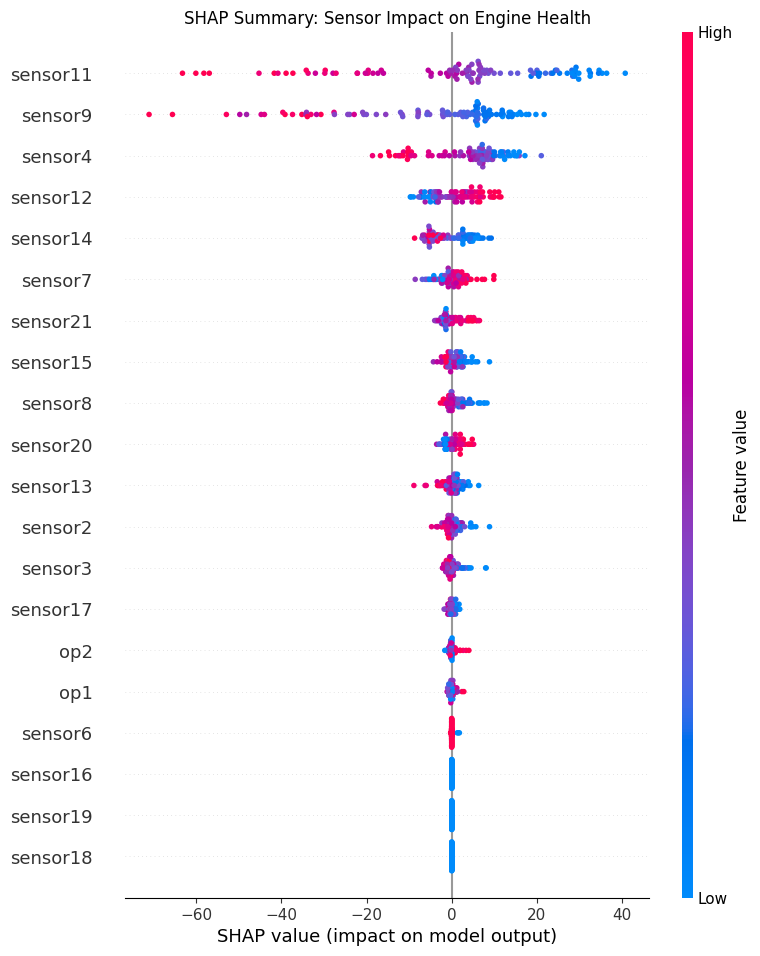

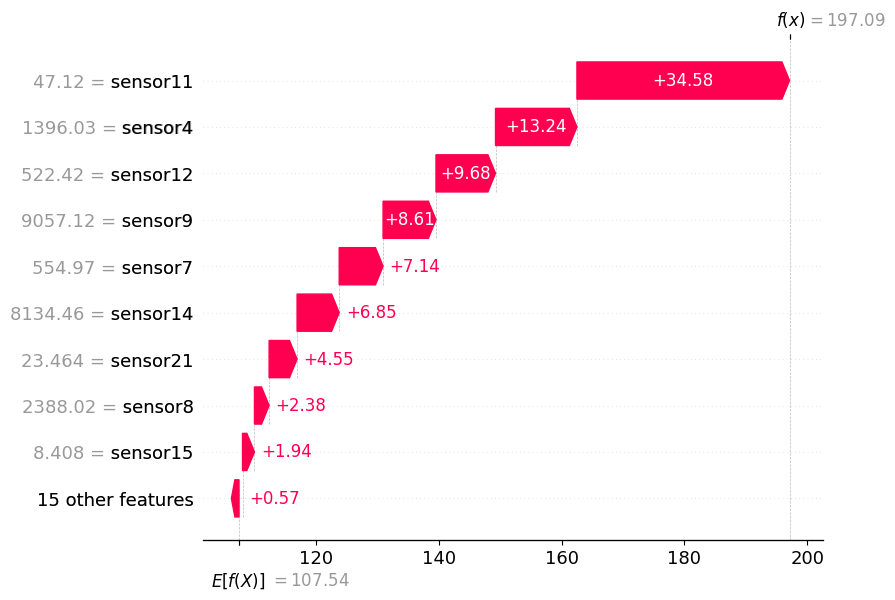

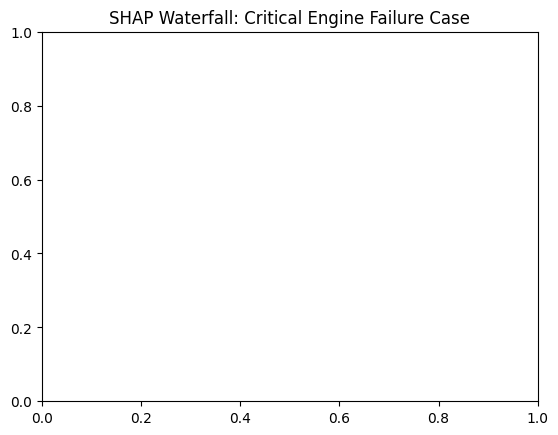

✅ DAY 1 COMPLETE: Plots saved!


In [9]:
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_test[:100])

# Summary Plot
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test[:100], feature_names=feature_cols, show=False)
plt.title("SHAP Summary: Sensor Impact on Engine Health")
plt.savefig('shap_summary.png', dpi=300, bbox_inches='tight')
plt.show()

# Waterfall Plot (worst case)
worst_idx = np.argmin(health_scores[:100])
plt.figure(figsize=(12, 6))
shap.waterfall_plot(shap.Explanation(
    values=shap_values[worst_idx],
    base_values=explainer.expected_value,
    data=X_test[worst_idx],
    feature_names=feature_cols
))
plt.title("SHAP Waterfall: Critical Engine Failure Case")
plt.savefig('shap_waterfall.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ DAY 1 COMPLETE: Plots saved!")

In [10]:
def get_health_and_explanation(input_array):
    """Rayyan's FastAPI function"""
    input_2d = input_array.reshape(1, -1)
    rul_pred = rf_model.predict(input_2d)[0]
    health_score = max(0, 100 - (rul_pred / 200) * 100)

    shap_val = explainer.shap_values(input_2d)[0]
    impacts = [(feature_cols[i], shap_val[i]) for i in range(len(shap_val))]
    top_3 = sorted(impacts, key=lambda x: abs(x[1]), reverse=True)[:3]

    return {
        "health_score": round(health_score, 1),
        "rul_cycles": round(rul_pred, 1),
        "diagnostics": [{"feature": f, "impact": round(i, 2)} for f, i in top_3]
    }

# Test
test_result = get_health_and_explanation(X_test[0])
print("✅ DAY 2 FUNCTION TEST:")
print(json.dumps(test_result, indent=2))

✅ DAY 2 FUNCTION TEST:
{
  "health_score": 32.3,
  "rul_cycles": 135.3,
  "diagnostics": [
    {
      "feature": "sensor4",
      "impact": 9.51
    },
    {
      "feature": "sensor20",
      "impact": 4.83
    },
    {
      "feature": "op2",
      "impact": 4.02
    }
  ]
}


In [11]:
%%writefile explain_model.py
import numpy as np
import joblib
import shap

# Production models (Rayyan provides)
rf_model = joblib.load('rf_model.pkl')
explainer = shap.TreeExplainer(rf_model)
feature_cols = ['op1','op2','op3','sensor1','sensor2','sensor3','sensor4','sensor5','sensor6',
                'sensor7','sensor8','sensor9','sensor10','sensor11','sensor12','sensor13',
                'sensor14','sensor15','sensor16','sensor17','sensor18','sensor19','sensor20','sensor21']

def get_health_and_explanation(input_array):
    input_2d = input_array.reshape(1, -1)
    rul_pred = rf_model.predict(input_2d)[0]
    health_score = max(0, 100 - (rul_pred / 200) * 100)
    shap_val = explainer.shap_values(input_2d)[0]

    impacts = [(feature_cols[i], shap_val[i]) for i in range(len(shap_val))]
    top_3 = sorted(impacts, key=lambda x: abs(x[1]), reverse=True)[:3]

    return {
        "health_score": round(health_score, 1),
        "diagnostics": [{"feature": f, "impact": round(i, 2)} for f, i in top_3]
    }

print("✅ explain_model.py SAVED!")

Writing explain_model.py
